<img src="images/nvidia_header.png" style="margin-left: -30px; width: 300px; float: left;">

# Accelerating Clustering Algorithms to Achieve the Highest Performance #

## Part 5: BERTopic ##

**Table of Contents**
<br>
BERTopic is a topic modeling technique that leverages BERT embeddings, UMAP, and HDBSCAN to generate interpretable topic clusters from textual data. It is particularly effective for extracting topics from large and unstructured text data. This notebook covers the below sections: 

1. [BERTopic](#BERTopic)

## BERTopic

[2025-08-18 04:31:33.940] [CUML] [info] cuML: Installed accelerator for sklearn.
[2025-08-18 04:31:38.011] [CUML] [info] cuML: Installed accelerator for umap.
[2025-08-18 04:31:38.023] [CUML] [info] cuML: Installed accelerator for hdbscan.
[2025-08-18 04:31:38.023] [CUML] [info] cuML: Successfully initialized accelerator.


README.md: 0.00B [00:00, ?B/s]

train-00000-of-00001.parquet:   0%|          | 0.00/21.0M [00:00<?, ?B/s]

test-00000-of-00001.parquet:   0%|          | 0.00/20.5M [00:00<?, ?B/s]

unsupervised-00000-of-00001.parquet:   0%|          | 0.00/42.0M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

... (10 outputs left out)

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

[2025-08-18 04:32:42.735] [CUML] [info] Building knn graph using brute force
[2025-08-18 04:32:52.645] [CUML] [info] build_algo set to brute_force_knn because random_state is given


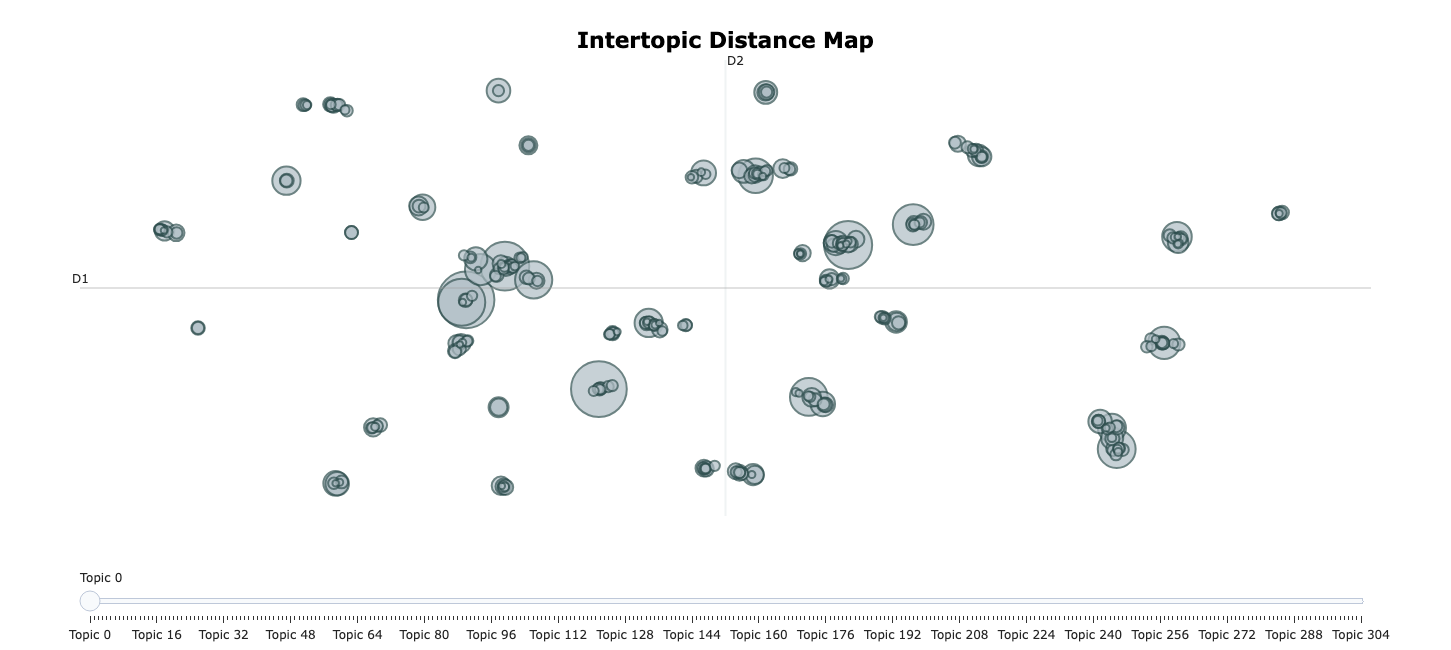

In [1]:
%load_ext cuml.accel

from bertopic import BERTopic
from hdbscan import HDBSCAN
from umap import UMAP
from datasets import load_dataset

# Load IMDb reviews dataset
dataset = load_dataset("imdb", split="train")
docs = dataset["text"]  # List of text documents

# Create instances of GPU-accelerated UMAP and HDBSCAN
umap_model = UMAP(n_components=5, n_neighbors=15, min_dist=0.0)
hdbscan_model = HDBSCAN(min_samples=10, gen_min_span_tree=True, prediction_data=True)

# Pass the above models to be used in BERTopic
topic_model = BERTopic(umap_model=umap_model, hdbscan_model=hdbscan_model)
topics, probs = topic_model.fit_transform(docs)

# Visualize the topics
topic_model.visualize_topics()

Get the Topic ID and the Respective Top Keywords

In [2]:
# Get the topic keywords
topic_info = topic_model.get_topic_info()  # Returns a DataFrame with topic details
topic_info  # Includes Topic ID and top keywords

,Topic,Count,Name,Representation,Representative_Docs
0,-1,16079,-1_the_to_and_of,"[the, to, and, of, this, it, is, in, that, br]",[We see a body of dead girl in a morgue with t...
1,0,384,0_japanese_martial_chinese_action,"[japanese, martial, chinese, action, arts, hon...",[By 1987 Hong Kong had given the world such fi...
2,1,373,1_show_season_episode_series,"[show, season, episode, series, episodes, show...","[""That '70s Show"" is definitely the funniest s..."
3,2,284,2_horror_scary_movie_movies,"[horror, scary, movie, movies, you, this, it, ...",[I probably give this more credit than it dese...
4,3,277,3_bad_movie_worst_was,"[bad, movie, worst, was, it, this, acting, you...",[I can't believe it that was the worst movie i...
...,...,...,...,...,...
301,300,5,300_marcel_lo_aymeric_aids,"[marcel, lo, aymeric, aids, hiv, family, gay, ...",[This film made for French TV deals with the t...
302,301,5,301_horse_dreamworks_horses_spirit,"[horse, dreamworks, horses, spirit, cimarron, ...",[Even though an animated film it really bored ...
303,302,5,302_fido_zombies_zombie_timmy,"[fido, zombies, zombie, timmy, moss, lassie, c...","[Fidois a very odd film. And in many ways, a v..."
304,303,5,303_slugs_spores_humans_secret,"[slugs, spores, humans, secret, systems, slugs...",[<br /><br />What is left of Planet Earth is p...


Get Detailed Keywords for Each Topic

In [3]:
# Get detailed keywords for each topic
for topic_id in set(topics):
    if topic_id != -1:  # Skip noise
        print(f"Topic {topic_id}:")
        print(topic_model.get_topic(topic_id))  # Returns keywords and their scores

Topic 0:
[('japanese', np.float64(0.0065075777210193645)), ('martial', np.float64(0.005926146543047742)), ('chinese', np.float64(0.005686954196262977)), ('action', np.float64(0.0045259048451562105)), ('arts', np.float64(0.0043973345683359765)), ('hong', np.float64(0.004288129910568446)), ('fu', np.float64(0.003919590889400673)), ('kong', np.float64(0.0038790609009360117)), ('fight', np.float64(0.0038488697785987085)), ('jackie', np.float64(0.003770427129693663))]
Topic 1:
[('show', np.float64(0.01893412949918077)), ('season', np.float64(0.0075700722650330005)), ('episode', np.float64(0.007211026850394323)), ('series', np.float64(0.006342131213053523)), ('episodes', np.float64(0.005963000733661057)), ('shows', np.float64(0.005754148016724112)), ('tv', np.float64(0.00463601266911303)), ('it', np.float64(0.0037947855549650654)), ('they', np.float64(0.003747723941996537)), ('funny', np.float64(0.003526203954791256))]
Topic 2:
[('horror', np.float64(0.012521644129232087)), ('scary', np.floa

Map Documents to Their Topics

In [4]:
# Map documents to their topics
doc_topics = [
    {
        "document": doc,
        "topic": topic_id,
        "keywords": topic_model.get_topic(topic_id) if topic_id != -1 else "Noise"
    }
    for doc, topic_id in zip(docs, topics)
]

# Convert to a readable format
for doc_topic in doc_topics[:10]:
    print(f"Document: {doc_topic['document']}")
    print(f"Assigned Topic: {doc_topic['topic']}")
    print(f"Keywords: {doc_topic['keywords']}")
    print()

Document: I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really had to see this for myself.<br /><br />The plot is centered around a young Swedish drama student named Lena who wants to learn everything she can about life. In particular she wants to focus her attentions to making some sort of documentary on what the average Swede thought about certain political issues such as the Vietnam War and race issues in the United States. In between asking politicians and ordinary denizens of Stockholm about their opinions on politics, she has sex with her drama teacher, classmates, and married men.<br /><br />What kills me about I AM CURIOUS-YELLOW is that 40 years ago, this was considered pornographic. Really, the sex and nudity scenes are few and far be

**Well Done!** Let's move to the [next notebook](06_Exercises.ipynb). 

<img src="images/nvidia_header.png" style="margin-left: -30px; width: 300px; float: left;">